# Intraday Bars

The engines step through the rows of `data` in order and don't care how far apart they
are. A row can be a day or a five-minute bar. Only the book's end-of-day tasks look at
the calendar: they run once per date, after its last row.

In [1]:
import time
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from yabte.backtest import Book, OHLCAsset, PositionalOrder, Strategy, StrategyRunner
from yabte.backtest.runner_cpp import yabte_cpp
from yabte.utilities.simulation.geometric_brownian_motion import gbm_simulate_paths

## Data

Simulated one-minute prices for two stocks, during US market hours (09:30 to 16:00)
over 20 weekdays, resampled to five-minute OHLC bars. Resampling also creates empty
bars for the nights and weekends. Drop them: they aren't trading time, and an empty bar
for a held stock would raise `MissingPriceError`.

A bar's timestamp is its start, so the 15:55 bar is the last of the day.

In [2]:
names = ["ACME", "BOLT"]
days = pd.bdate_range("2025-01-06", periods=20)
minutes = pd.timedelta_range("09:30:00", "15:59:00", freq="1min")
ticks = pd.DatetimeIndex([day + minute for day in days for minute in minutes])

paths = gbm_simulate_paths(
    S0=np.array([100.0, 50.0]),
    mu=np.array([0.05, 0.05]),
    sigma=np.array([0.3, 0.4]),
    R=np.identity(2),
    T=len(days) / 252,
    n_steps=len(ticks),
    n_sims=1,
    rng=np.random.default_rng(42),
)
prices = pd.DataFrame(paths[:, 0, :], index=ticks, columns=names)

data = (
    prices.resample("5min").ohlc().dropna(how="all").rename(columns=str.title, level=1)
)
assets = [OHLCAsset(name=name) for name in names]

print(f"{len(data)} bars, {len(data) // len(days)} a day")
data.head()

1560 bars, 78 a day


ACME                                      \
                           Open        High         Low       Close   
2025-01-06 09:30:00  100.000000  100.101042   99.914317   99.926546   
2025-01-06 09:35:00   99.924945  100.095492   99.924945  100.095492   
2025-01-06 09:40:00  100.179681  100.289216  100.161965  100.289216   
2025-01-06 09:45:00  100.328842  100.544681  100.328842  100.533723   
2025-01-06 09:50:00  100.454434  100.556974  100.454434  100.556974   

                          BOLT                                   
                          Open       High        Low      Close  
2025-01-06 09:30:00  50.000000  50.000000  49.890460  49.890460  
2025-01-06 09:35:00  49.836168  49.957429  49.836168  49.841631  
2025-01-06 09:40:00  49.838441  49.838441  49.762928  49.786123  
2025-01-06 09:45:00  49.813485  49.813485  49.735956  49.754259  
2025-01-06 09:50:00  49.795565  49.872930  49.795565  49.872930

## Timing within a bar

Each bar runs the same steps as a day does:

1. `on_open()`, with the bar's High, Low and Close hidden.
2. Queued orders execute at the bar's traded price. For `OHLCAsset` that's the midpoint
   of High and Low.
3. `on_close()`, with the whole bar visible. Orders placed here wait for the next bar.
4. On the day's last bar only, each book's end-of-day tasks: interest, and valuing
   positions at the close for `book_history`.

So a signal computed from a bar's close fills on the following bar. An order placed in
`on_open` fills on the bar it was placed on.

## Opening range breakout

The strategy watches the first 30 minutes of each day, the opening range. After that, a
close above the range's high takes a long position of 100 shares and a close below its
low takes a short one. `PositionalOrder` trades to a target position, so repeating a
signal does nothing and an opposite signal flips the position. Every order carries
`key=name`, which drops an older queued order for the same stock in favour of the
newer one.

Positions are closed in `on_open` of each day's last bar, which fills on that bar.
Nothing is held overnight. `init()` runs before the first bar and sees the whole of
`data`, so it can list each day's last bar up front. That's lookahead, but harmless
here: a session's closing time is known in advance. Finding the last bar from the
calendar rather than hardcoding 15:55 also copes with half days.

In [3]:
OPENING_BARS = 6  # 30 minutes


class OpeningRangeBreakout(Strategy):
    def init(self):
        ts = self.data.index.to_series()
        self.last_bars = set(ts.groupby(ts.index.date).max())

    def on_open(self):
        if self.ts in self.last_bars:
            for name in names:
                self.orders.append(PositionalOrder(asset_name=name, size=0, key=name))

    def on_close(self):
        today = self.data.loc[self.ts.normalize() :]
        if len(today) <= OPENING_BARS or self.ts in self.last_bars:
            return

        for name in names:
            opening = today[name].iloc[:OPENING_BARS]
            close = today[name].Close.iloc[-1]
            if close > opening.High.max():
                target = 100
            elif close < opening.Low.min():
                target = -100
            else:
                continue
            self.orders.append(PositionalOrder(asset_name=name, size=target, key=name))

Run it on both engines, if the C++ one is built, and check they make the same trades.

In [4]:
def run(engine):
    sr = StrategyRunner(
        data=data,
        assets=assets,
        strategies=[OpeningRangeBreakout()],
        books=[Book(name="Main", cash="100000")],
        engine=engine,
    )
    start = time.perf_counter()
    srr = sr.run()
    print(f"{engine}: {time.perf_counter() - start:.2f}s")
    return srr


def trades(srr):
    th = srr.transaction_history
    return pd.DataFrame(
        {
            # the engines return different timestamp resolutions
            "ts": th.ts.astype("datetime64[ns]").values,
            "asset": th.asset_name.values,
            "quantity": th.quantity.astype(float).values,
            "price": th.price.astype(float).values,
        }
    )


srr = run("python")
if yabte_cpp is not None:
    srr_cpp = run("cpp")
    pd.testing.assert_frame_equal(trades(srr), trades(srr_cpp))
    print(f"{len(srr.transaction_history)} trades, identical on both engines")
else:
    print(f"{len(srr.transaction_history)} trades (C++ engine not built)")

python: 2.49s


cpp: 2.49s
200 trades, identical on both engines


One day of ACME. The shaded band is the opening range. A flip from long to short is two
trades on the same bar, one closing the old position and one opening the new.

,asset,quantity,price
ts,,,
2025-01-06 10:20:00,ACME,-100.0,99.69
2025-01-06 12:15:00,ACME,100.0,100.63
2025-01-06 12:15:00,ACME,100.0,100.63
2025-01-06 13:50:00,ACME,-100.0,100.09
2025-01-06 13:50:00,ACME,-100.0,100.09
2025-01-06 15:55:00,ACME,100.0,99.17


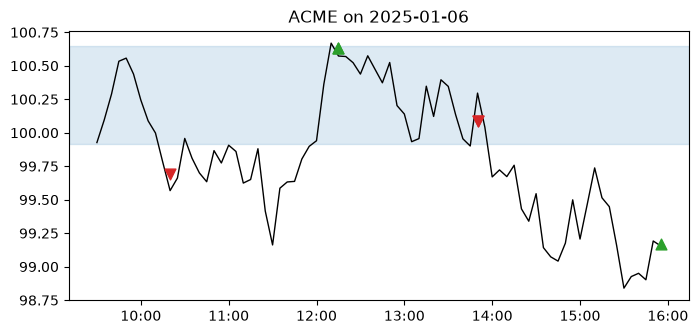

In [5]:
day = "2025-01-06"
bars = data.loc[day, "ACME"]
opening = bars.iloc[:OPENING_BARS]
th = trades(srr).query("asset == 'ACME'").set_index("ts").loc[day]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(bars.index, bars.Close, color="k", lw=1, label="close")
ax.axhspan(opening.Low.min(), opening.High.max(), color="C0", alpha=0.15)
for side, color, marker in [(1, "C2", "^"), (-1, "C3", "v")]:
    fills = th[np.sign(th.quantity) == side]
    ax.scatter(fills.index, fills.price, color=color, marker=marker, s=60, zorder=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title(f"ACME on {day}")
th

## Daily book, intraday equity

`book_history` has a row per day, not per bar, because the book only values its
positions at the end of the day. The row is stamped with the day's last bar.

In [6]:
print(f"{len(data)} bars, {len(srr.book_history)} rows in book_history")
srr.book_history.head(3)

1560 bars, 20 rows in book_history


Main               
                         cash  mtm     total
ts                                          
2025-01-06 15:55:00   99989.0  0.0   99989.0
2025-01-07 15:55:00   99786.0  0.0   99786.0
2025-01-08 15:55:00  100105.0  0.0  100105.0

For an intraday equity curve, rebuild positions and cash per bar from the trades and
value the positions at each bar's close. At the day's last bar it should agree with
`book_history`. Here that's trivially true, as the book is flat at every close, but the
check also covers interest when `Book.rate` isn't zero, because interest is booked as a
transaction too.

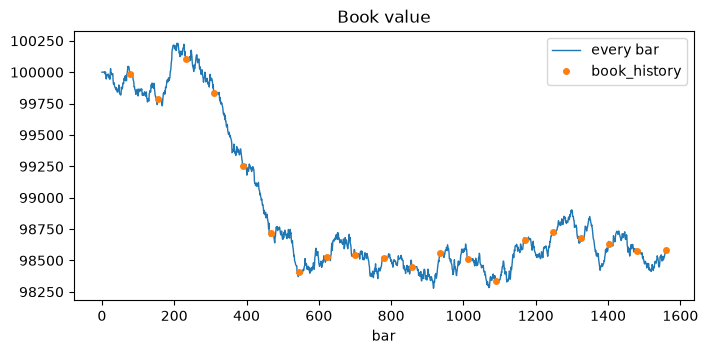

In [7]:
th = srr.transaction_history.astype({"ts": data.index.dtype})
closes = data.xs("Close", axis=1, level=1)

flows = th.groupby("ts").total.sum().astype(float)
cash = 100_000 + flows.reindex(data.index, fill_value=0.0).cumsum()

positions = (
    th.dropna(subset=["asset_name"])
    .pivot_table(index="ts", columns="asset_name", values="quantity", aggfunc="sum")
    .reindex(data.index)
    .fillna(0)
    .astype(float)
    .cumsum()
)
equity = cash + (positions * closes[positions.columns]).sum(axis=1)

eod = srr.book_history.Main.total.astype(float)
pd.testing.assert_series_equal(
    equity.loc[eod.index], eod, check_names=False, check_index_type=False
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(len(equity)), equity.values, lw=1, label="every bar")
ax.plot(
    equity.index.get_indexer(eod.index), eod.values, "o", ms=4, label="book_history"
)
ax.set_xlabel("bar")
ax.set_title("Book value")
ax.legend();

The x axis counts bars rather than time, which leaves out the gaps for nights and
weekends. Simulated prices have no trend for a breakout to catch, so the loss says
nothing about the strategy.

## Caveats

- Every fill is at the bar's traded price. A limit or stop order built on
  `pre_execute_check` (see Orders & Assets) decides whether to fill on that price, and
  fills at it rather than at its own level. Custom order classes also only run on the
  Python engine.
- Days end at midnight. A session that runs past it, like many futures markets, is
  split into two days for interest and `book_history`.
- Days are dates in the index's own timezone. A naive index in the exchange's local
  time, or one localized to the exchange's timezone, gives its trading days. A UTC
  index splits a New York evening session across two days.
- `Book.rate` is per day, whatever the bar size.